# Buy now or wait? Modelling flight price drops


**How "wait" works here:** waiting = setting a price alert at −3% and waiting up to N days
(N depends on how far away the flight is: 3–20 days). If the price drops by 3%+ inside the
window, I buy at that price. If not, I buy at the last price in the window.

**Metric:** average % saved compared to buying immediately.
- `always buy` = 0% (the baseline)
- `oracle` = buying at the lowest price in the window (perfect foresight, the ceiling)

**Data:** ~10M price observations from my own Google Flights scraper (Jul 2025 – Apr 2026),
split by time: train → validation → test, with a gap so no label leaks across splits.

In [51]:
import pandas as pd
import numpy as np
import lightgbm as lgb
pd.set_option('display.max_columns', None)

import matplotlib.pyplot as plt


MODEL, RULE, ORACLE = "#2a78d6", "#eb6834", "#c9c8c2"   # blue, orange, light gray

plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "axes.prop_cycle": plt.cycler(color=[MODEL, RULE, ORACLE]),
    "legend.frameon": False,
    "axes.titlesize": 14, "axes.titleweight": "semibold", "axes.titlelocation": "left",
})

In [59]:
df = pd.read_parquet("model_dataset.parquet")
df['window_end'] = df['price_datetime'] + pd.to_timedelta(np.minimum(df['window_N'], df['dtd']), unit='D')

In [34]:
# add price features
def add_price_features(df):
    p = df.sort_values(["itinerary_id", "price_datetime"]).copy()
    g = df.groupby("itinerary_id", sort=False)

    p['days_since_prev'] = (p['price_datetime']-g['price_datetime'].shift(1)).dt.total_seconds() / 86400
    p["chg_2_%"] = (p['price'] /g["price"].shift(2) - 1) * 100

    p['n_past_obs'] = g.cumcount()
    p['vs_max_so_far_%'] = (p['price'] / g['price'].cummax() - 1) * 100

    return p
df = add_price_features(df)

VAL_START  = pd.Timestamp("2025-10-07")
TEST_START = pd.Timestamp("2025-11-11")
TEST_END   = pd.Timestamp("2026-04-15")

train_df = df[df["window_end"] < VAL_START].copy()                              # label fully known before val
val_df  = df[(df["price_datetime"] >= VAL_START) & (df["window_end"] < TEST_START)].copy()
test_df  = df[(df["price_datetime"] >= TEST_START) & (df["window_end"] <= TEST_END)].copy()
print(f"dropped by gap: {len(df) - len(train_df) - len(val_df) - len(test_df):,}")
print(f"train: {len(train_df):,}, val: {len(val_df):,}, test: {len(test_df):,}")

print(f"Train percent: {len(train_df) / len(df):.2%}, val percent: {len(val_df) / len(df):.2%}, test percent: {len(test_df) / len(df):.2%}")

# add price features 
med = train_df.groupby(["src", "dst", "bucket"], observed=True)["price"].median().rename("route_med")
for p in (train_df, val_df, test_df):
    p["route_med"] = p.join(med, on=["src", "dst", "bucket"])["route_med"].to_numpy()
    p["price_vs_route_%"] = 100 * (p["price"] / p["route_med"] - 1)

del df


dropped by gap: 1,535,474
train: 8,696,882, val: 1,306,727, test: 1,434,438
Train percent: 67.04%, val percent: 10.07%, test percent: 11.06%


In [35]:
# check whether the splits are correct
print('Windows splits check (train < val < test):')
print(train_df["window_end"].max() < val_df["price_datetime"].min(), val_df["window_end"].max() < test_df["price_datetime"].min())

print('\nTrain/val/test sizes and wait mean:')
parts = {"train": train_df, "val": val_df, "test": test_df}
print(pd.concat({n: p.groupby("bucket")["wait"].agg(["size", "mean"]) for n, p in parts.items()}, axis=1).round(3))


Windows splits check (train < val < test):
True True

Train/val/test sizes and wait mean:
          train            val           test       
           size   mean    size   mean    size   mean
bucket                                              
3        186900  0.175   20022  0.205    9529  0.209
7       1135213  0.221  192069  0.206  192752  0.186
14      1149848  0.262  200035  0.219  180252  0.201
30      2269236  0.298  377812  0.226  328383  0.217
60      2166879  0.337  312458  0.277  468798  0.270
90      1788806  0.382  204331  0.322  254724  0.370


In [36]:
train, val, test = [p.copy() for p in (train_df, val_df, test_df)]  # avoid SettingWithCopyWarning

PRICE_FEATS = ["chg_1_%", "vs-min_so_far_%", "mean_abs_chg_so_far", "price_vs_route_%", "n_past_obs", "vs_max_so_far_%", 'days_since_prev', "chg_2_%"] 
NUM = ["price", "dtd", "travel_time", "dep_hour", "dep_dayofweek", "dep_month"]
CAT = ["airline_name", "region_from", "region_to"]
FEATS = NUM + CAT + PRICE_FEATS 

for c in CAT:                                   # categories chosen on train only
    keep = list(train[c].astype(str).value_counts().index[:20])
    for p in (train, val, test):
        s = p[c].astype(str)
        p[c] = pd.Categorical(s.where(s.isin(keep), "Other"), categories=keep + ["Other"])

print(display(train[FEATS].head(3)))


,price,dtd,travel_time,dep_hour,dep_dayofweek,dep_month,airline_name,region_from,region_to,chg_1_%,vs-min_so_far_%,mean_abs_chg_so_far,price_vs_route_%,n_past_obs,vs_max_so_far_%,days_since_prev,chg_2_%
0,40.029999,26,190,10,2,7,Other,Eastern,Western,NaN,0.000000,NaN,-85.043900,0,0.000000,NaN,NaN
1,69.980003,23,190,10,2,7,Other,Eastern,Western,74.818893,74.818893,74.818893,-73.853912,1,0.000000,3.071088,NaN
2,60.060001,17,190,10,2,7,Other,Eastern,Western,-14.175481,50.037479,44.497189,-77.560249,2,-14.175481,6.056018,50.037479


None


### Features:
- **Flight:** price, days to departure, travel time, departure hour / weekday / month
- **Context:** airline, origin and destination region
- **Price history of this exact flight (past only):** last change, change over 2 scrapes,
  price vs the lowest and highest seen so far, volatility, number of past observations
- **Route norm:** price vs the median price of this route, *computed on train only*

In [37]:
# function to compute price gain in percent (price - cost_wait) / price
def gain(p):
    return 100 * ((p["price"] - p["cost_wait"]) / p["price"])

In [38]:
g_tr, g_va = gain(train).clip(-50, 50), gain(val).clip(-50, 50)

model_cs = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=63,
                           min_child_samples=200, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, random_state=42, verbose=-1)
model_cs.fit(train[FEATS], (g_tr > 0).astype(int), sample_weight=g_tr.abs() + 0.1,
             eval_X=val[FEATS], eval_y=(g_va > 0).astype(int), eval_sample_weight=[g_va.abs() + 0.1],
             callbacks=[lgb.early_stopping(200), lgb.log_evaluation(200)])
p_val_cs = model_cs.predict_proba(val[FEATS])[:, 1]

def saving(wait_mask, part):
    paid = np.where(wait_mask, part["cost_wait"], part["price"])
    return 100 * ((part["price"] - paid) / part["price"]).mean()

p_val = model_cs.predict_proba(val[FEATS])[:, 1]
for thr in np.arange(0.30, 0.80, 0.05):          # tune on VAL only
    w = p_val >= thr
    print(f"thr {thr:.2f}  saving {saving(w, val):6.2f}%  wait share {w.mean():.3f}")


Training until validation scores don't improve for 200 rounds
[200]	valid_0's binary_logloss: 0.419319
[400]	valid_0's binary_logloss: 0.413711
[600]	valid_0's binary_logloss: 0.411473
[800]	valid_0's binary_logloss: 0.410375
[1000]	valid_0's binary_logloss: 0.410093
[1200]	valid_0's binary_logloss: 0.409564
[1400]	valid_0's binary_logloss: 0.409595
Early stopping, best iteration is:
[1202]	valid_0's binary_logloss: 0.40955
thr 0.30  saving  -1.36%  wait share 0.386
thr 0.35  saving  -0.75%  wait share 0.333
thr 0.40  saving  -0.30%  wait share 0.285
thr 0.45  saving   0.01%  wait share 0.242
thr 0.50  saving   0.24%  wait share 0.203
thr 0.55  saving   0.40%  wait share 0.166
thr 0.60  saving   0.48%  wait share 0.133
thr 0.65  saving   0.50%  wait share 0.103
thr 0.70  saving   0.49%  wait share 0.076
thr 0.75  saving   0.43%  wait share 0.053


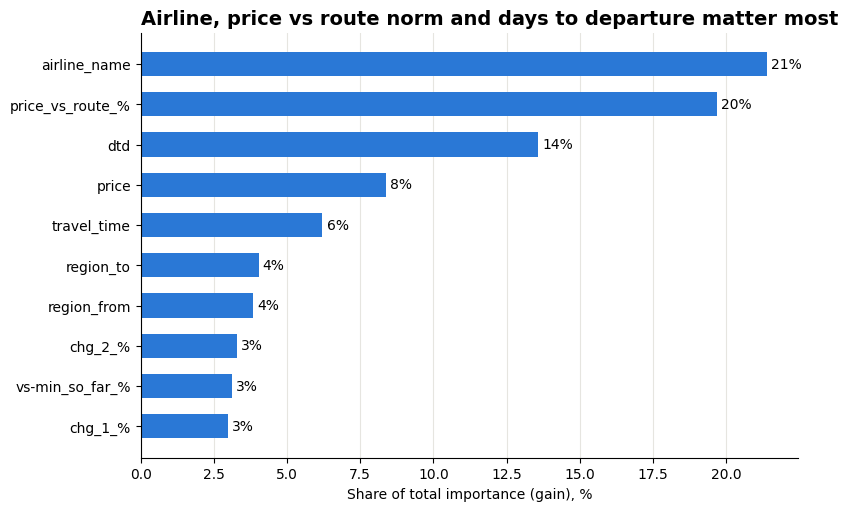

In [73]:
imp = pd.Series(model_cs.booster_.feature_importance("gain"), index=FEATS)
imp = (100 * imp / imp.sum()).sort_values().tail(10)

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.barh(imp.index, imp.values, color=MODEL, height=0.6)
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Share of total importance (gain), %")
ax.set_title("Airline, price vs route norm and days to departure matter most")
fig.savefig("05_feature_importance.png", dpi=150, bbox_inches="tight")

### What the model looks at
The airline, how expensive this price is compared to the usual price for the route,
and days to departure explain more than half of the model's decisions.
Recent price moves (`chg_1`, `chg_2`, `vs-min`) add a bit on top.

### Model
LightGBM predicts "will waiting save money?". Not all mistakes cost the same: missing a 20% drop
hurts much more than missing a 1% drop. So each row is weighted by how much money is at stake
(`|gain|`). The model learns to care about big drops, not just frequent ones.

The decision threshold is tuned **on validation only** → **0.65**.
The model says "wait" only when it's fairly confident, on ~9% of searches.

In [22]:
def results_table(policies, part):
    row_gain = 100 * (part["price"] - part["cost_wait"]) / part["price"]
    res = pd.DataFrame({n: np.where(m, row_gain, 0.0) for n, m in policies.items()}, index=part.index)
    res["oracle"] = 100 * (part["price"] - np.minimum(part["price"], part["window_min"])) / part["price"]
    table = res.groupby(part["bucket"]).mean()
    table.loc["ALL"] = res.mean()
    return table.round(2)

In [41]:
p_test = model_cs.predict_proba(test[FEATS])[:, 1]
policies = {
    "always buy":  np.zeros(len(test), bool),
    "always wait": np.ones(len(test), bool),
    "model":       p_test >= 0.65,
}
result = results_table(policies, test)
print(result)

        always buy  always wait  model  oracle
bucket                                        
3              0.0    -9.700000   1.15    4.60
7              0.0   -18.480000   0.34    3.89
14             0.0   -21.450001   0.23    4.03
30             0.0   -15.270000   0.12    4.48
60             0.0   -12.680000  -0.00    5.56
90             0.0    -0.460000   1.08    7.91
ALL            0.0   -12.960000   0.30    5.31


### Test results (Nov 11 – Apr 15, the last period)
- **Always waiting loses ~13%**: prices mostly go up as departure gets closer.
- **The model saves +0.30%** on average, best at 3 days (+1.15%) and 90 days (+1.08%).
- **The oracle could save ~5%**, so most drops are not predictable from this data.
- The scraper ran only every 4–8 days in this period. The other test periods are in the rolling evaluation below.

## Things I tried that didn't work

- regression, 
- classifier + regression, 
- bucket specific treshold, 
- equential policy.

In [41]:
val_gain = gain(val).to_numpy()
best_thr = {}
for b, idx in val.groupby("bucket").indices.items():
    sweep = {round(t, 2): np.where(p_val_cs[idx] >= t, val_gain[idx], 0).mean()
             for t in np.arange(0.30, 0.96, 0.05)}
    t = max(sweep, key=sweep.get)
    best_thr[b] = t if sweep[t] > 0 else 1.01      # 1.01 = never wait in this bucket

print("Bucket-specific thresholds:")
for b, t in best_thr.items():
    print(f"Bucket {b}: Threshold = {t:.2f}")
wait_bucket = p_test >= test["bucket"].map(best_thr).to_numpy()


policies = {
    "always buy":   np.zeros(len(test), bool),
    "always wait":  np.ones(len(test), bool),
    "rule":         ((test["dtd"] > 60) & (test["chg_1_%"] > 3)).to_numpy(),
    "model (0.65)": p_test >= 0.65,
    "model (per-bucket)": wait_bucket,
}

key = lambda p: p["airline_name"].astype(str) + "|" + p["bucket"].astype(str)
seg = gain(val).groupby(key(val)).agg(["mean", "size"])
good = ["Ryanair|90"]                                  # stable on train AND val
policies["segment rule"] = key(test).isin(good).to_numpy()
policies["model + Ryanair90"] = policies["model (0.65)"] | policies["segment rule"]
print(results_table(policies, test))

Bucket-specific thresholds:
Bucket 3: Threshold = 0.50
Bucket 7: Threshold = 0.60
Bucket 14: Threshold = 0.65
Bucket 30: Threshold = 0.65
Bucket 60: Threshold = 0.70
Bucket 90: Threshold = 0.70
        always buy  always wait  rule  model (0.65)  model (per-bucket)  \
bucket                                                                    
3              0.0    -9.710000  0.00          1.11                0.96   
7              0.0   -18.670000  0.00          0.76                0.72   
14             0.0   -24.469999  0.00          0.24                0.24   
30             0.0   -19.290001  0.00         -0.19               -0.19   
60             0.0   -12.980000  0.00          0.30                0.39   
90             0.0    -5.910000 -0.92         -0.01                0.24   
ALL            0.0   -16.240000 -0.14          0.18                0.23   

        segment rule  model + Ryanair90  oracle  
bucket                                           
3               0.00          

In [14]:

reg = lgb.LGBMRegressor(objective="regression", alpha=5, n_estimators=2000, learning_rate=0.05,
                        num_leaves=63, min_child_samples=200, subsample=0.8, subsample_freq=1,
                        colsample_bytree=0.8, random_state=42, verbose=-1)
reg.fit(train[FEATS], g_tr, eval_set=[(val[FEATS], g_va)],
        callbacks=[lgb.early_stopping(200), lgb.log_evaluation(200)])
pv = reg.predict(val[FEATS])
for m in [0, 1, 2, 3, 5]:
    w = pv > m
    print(f"margin {m}: saving {saving(w, val):.2f}%  wait share {w.mean():.3f}")

g:\pet-projects\google-flight-scraper\myenv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[200]	valid_0's l2: 477.685
[400]	valid_0's l2: 472.423
[600]	valid_0's l2: 468.649
[800]	valid_0's l2: 466.768
[1000]	valid_0's l2: 465.606
[1200]	valid_0's l2: 464.667
[1400]	valid_0's l2: 463.939
[1600]	valid_0's l2: 463.561
[1800]	valid_0's l2: 463.278
[2000]	valid_0's l2: 462.812
Did not meet early stopping. Best iteration is:
[2000]	valid_0's l2: 462.812
margin 0: saving 0.10%  wait share 0.211
margin 1: saving 0.20%  wait share 0.185
margin 2: saving 0.28%  wait share 0.161
margin 3: saving 0.33%  wait share 0.140
margin 5: saving 0.39%  wait share 0.103


In [16]:
p_test_cs  = model_cs.predict_proba(test[FEATS])[:, 1]
p_test_reg = reg.predict(test[FEATS])

ryanair90 = (test["airline_name"].astype(str).eq("Ryanair") & test["bucket"].eq(90)).to_numpy()

policies = {
    "always buy":          np.zeros(len(test), bool),
    "always wait":         np.ones(len(test), bool),
    "classifier (0.65)":   p_test_cs >= 0.65,
    "regression (>5%)":    p_test_reg > 5,
    "classifier + regression":   (p_test_cs >= 0.65) | (p_test_reg > 5),
}
table = results_table(policies, test)
print(table)

# how often each policy says "wait": important context for the savings
print(pd.Series({n: m.mean() for n, m in policies.items()}, name="wait share").round(3))

        always buy  always wait  classifier (0.65)  regression (>5%)  \
bucket                                                                 
3              0.0    -9.700000               1.06              1.18   
7              0.0   -18.480000               0.34              0.33   
14             0.0   -21.450001               0.21              0.20   
30             0.0   -15.440000               0.09              0.10   
60             0.0   -12.680000              -0.04             -0.03   
90             0.0    -0.460000               1.10              0.92   
ALL            0.0   -13.010000               0.28              0.25   

        classifier + regression  oracle  
bucket                                   
3                          1.18    4.60  
7                          0.35    3.89  
14                         0.19    4.03  
30                         0.07    4.46  
60                        -0.09    5.56  
90                         1.16    7.91  
ALL            

**Regression (predict the % saving directly, wait if > X%).** Didn't beat the classifier on test,
and combining the two didn't help either. The classifier with cost weights is simpler and at least as good.

In [28]:
def sequential_policy(test, mask):
    # Sequential policy simulation the buyer decides again at every scrape and buys at the first "buy" signal
    df = pd.DataFrame({
        "itinerary_id": test["itinerary_id"],
        "price_datetime": test["price_datetime"],
        "price": test["price"],
        "decision": mask,
        "buy_price": None,   # to be filled
        "bucket": test["bucket"],
    }) 

    df = df.sort_values(["itinerary_id", "price_datetime"])
    by_itin = df['itinerary_id']

    df['buy_price'] = df['price'].where(~df['decision'])
    df['paid'] = df['buy_price'].groupby(by_itin, sort=False).bfill() # find the next non NaN price
    df["paid"] = df["paid"].fillna(df.groupby(by_itin, sort=False)["price"].transform("last"))

    df['saving_%'] = 100 * (df['price'] - df['paid']) / df['price']

    df["future_min"] = df[::-1].groupby("itinerary_id", sort=False)["price"].cummin()
    df["oracle_%"] = 100 * (df["price"] - df["future_min"]) / df["price"]
    return df

seq = {n: sequential_policy(test, m) for n, m in policies.items()}

table = pd.DataFrame({n: s.groupby("bucket")["saving_%"].mean() for n, s in seq.items()})
table.loc["ALL"] = {n: s["saving_%"].mean() for n, s in seq.items()}
s0 = seq["always buy"]
table["oracle"] = list(s0.groupby("bucket")["oracle_%"].mean()) + [s0["oracle_%"].mean()]
print(table.round(2))

        always buy  always wait  classifier (0.65)  regression (>5%)  \
bucket                                                                 
3              0.0     0.000000               0.00              0.00   
7              0.0    -3.170000               0.06              0.05   
14             0.0    -6.850000               0.13              0.13   
30             0.0   -18.030001              -0.09             -0.09   
60             0.0   -32.540001              -0.60             -0.64   
90             0.0   -66.199997              -1.35             -1.03   
ALL            0.0   -27.780001              -0.43             -0.39   

        classifier + regression  oracle  
bucket                                   
3                          0.00    0.00  
7                          0.06    0.89  
14                         0.14    1.77  
30                        -0.13    2.04  
60                        -0.81    3.64  
90                        -1.63    6.48  
ALL            

**Asking the model again at every scrape.** A buyer who re-checks the model at every new price
and buys at the first "buy" signal **loses money (−0.4%)**. The model is trained for a
one-time decision with a fixed waiting window. Re-asking it changes the horizon it was trained for.

The model captures a small but positive part of the possible saving at almost every horizon.
It's strongest very close to departure (3–7 days) and far out (60–90 days).
The 30-day horizon is slightly negative, so the model has no edge there.

In [60]:
PARAMS = dict(n_estimators=2000, learning_rate=0.05, num_leaves=63, min_child_samples=200,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)

def prepare(train, others):
    """Fit route medians + top categories on train only, apply to all parts."""
    med = train.groupby(["src", "dst", "bucket"], observed=True)["price"].median().rename("route_med")
    parts = []
    for p in [train] + others:
        p = p.copy()
        p["route_med"] = p.join(med, on=["src", "dst", "bucket"])["route_med"].to_numpy()
        p["price_vs_route_%"] = 100 * (p["price"] / p["route_med"] - 1)
        parts.append(p)
    for c in CAT:
        keep = list(parts[0][c].astype(str).value_counts().index[:20])
        for p in parts:
            s = p[c].astype(str)
            p[c] = pd.Categorical(s.where(s.isin(keep), "Other"), categories=keep + ["Other"])
    return parts

def run_fold(val_start, test_start, test_end):
    val_start, test_start, test_end = map(pd.Timestamp, (val_start, test_start, test_end))
    tr = df[df["window_end"] < val_start]
    va = df[(df["price_datetime"] >= val_start) & (df["window_end"] < test_start)]
    te = df[(df["price_datetime"] >= test_start) & (df["window_end"] < test_end)]
    tr, va, te = prepare(tr, [va, te])

    g_tr, g_va = gain(tr).clip(-50, 50), gain(va).clip(-50, 50)
    m = lgb.LGBMClassifier(**PARAMS)
    m.fit(tr[FEATS], (g_tr > 0).astype(int), sample_weight=g_tr.abs() + 0.1,
          eval_X=va[FEATS], eval_y=(g_va > 0).astype(int), eval_sample_weight=[g_va.abs() + 0.1],
          callbacks=[lgb.early_stopping(200, verbose=False)])

    p_va = m.predict_proba(va[FEATS])[:, 1]                 # threshold: tuned on this fold's val
    thrs = np.arange(0.40, 0.86, 0.05)
    thr = thrs[int(np.argmax([saving(p_va >= t, va) for t in thrs]))]

    p_te = m.predict_proba(te[FEATS])[:, 1]
    pol = {"always buy": np.zeros(len(te), bool), "always wait": np.ones(len(te), bool), "model": p_te >= thr}
    print(f"test {test_start.date()} → {test_end.date()} | train {len(tr):,} val {len(va):,} "
          f"test {len(te):,} | thr {thr:.2f} | trees {m.best_iteration_}")
    return results_table(pol, te)


In [61]:
df = add_price_features(df)

FOLDS = [  # (val_start, test_start, test_end)
    ("2025-07-20", "2025-08-15", "2025-09-10"),
    ("2025-08-15", "2025-09-10", "2025-10-07"),
    ("2025-09-10", "2025-10-07", "2025-11-11"),   
    ("2025-10-07", "2025-11-11", "2026-04-15"),   # sparse period = stress test
]
tables = {f[1]: run_fold(*f) for f in FOLDS}

summary = pd.DataFrame({k: t["model"] for k, t in tables.items()})
summary["mean"] = summary.iloc[:, :3].mean(axis=1)   # mean over the 3 dense folds
print(summary.round(2))
print(pd.DataFrame({k: t["oracle"] for k, t in tables.items()}).round(2))   # ceiling per fold

test 2025-08-15 → 2025-09-10 | train 1,200,858 val 1,351,137 test 1,205,054 | thr 0.65 | trees 523
test 2025-09-10 → 2025-10-07 | train 3,919,477 val 1,205,054 test 1,269,342 | thr 0.65 | trees 984
test 2025-10-07 → 2025-11-11 | train 6,275,468 val 1,269,342 test 1,306,727 | thr 0.65 | trees 1950
test 2025-11-11 → 2026-04-15 | train 8,696,882 val 1,306,727 test 1,434,438 | thr 0.65 | trees 1202
        2025-08-15  2025-09-10  2025-10-07  2025-11-11  mean
bucket                                                      
3             0.68        1.02        1.11        1.15  0.94
7             0.42        0.84        0.76        0.34  0.67
14            0.00        0.21        0.24        0.23  0.15
30           -0.48        0.12       -0.19        0.12 -0.18
60            0.21        0.53        0.30       -0.00  0.35
90            1.27        0.92       -0.01        1.08  0.73
ALL           0.13        0.47        0.18        0.30  0.26
        2025-08-15  2025-09-10  2025-10-07  2025-11-1

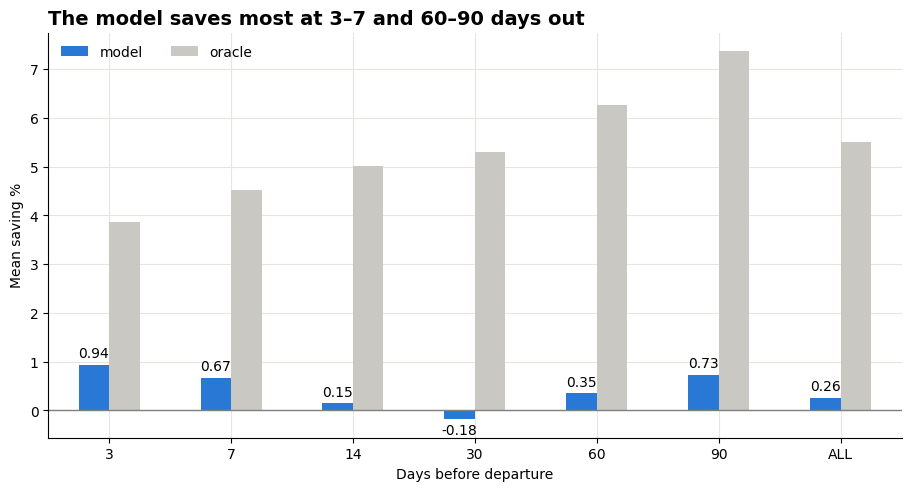

In [71]:
fig, ax = plt.subplots(layout='constrained')
oracle = pd.DataFrame({k: t["oracle"] for k, t in tables.items()}).iloc[:, :3].mean(axis=1)
result = pd.DataFrame({"model": summary["mean"], "oracle": oracle})
result[['model', 'oracle']].plot(kind='bar', ax=ax, color=[MODEL, ORACLE], rot=0)   # + colors, horizontal labels

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)   # numbers only on the model
ax.set_ylabel("Mean saving %")
ax.set_xlabel("Days before departure")
ax.set_title("The model saves most at 3–7 and 60–90 days out")   # title = conclusion
ax.axhline(0, color="gray", linewidth=1)
ax.legend(loc='upper left', ncols=2)

fig.savefig(fname = "01_saving_by_horizon.png", dpi=150, bbox_inches="tight")

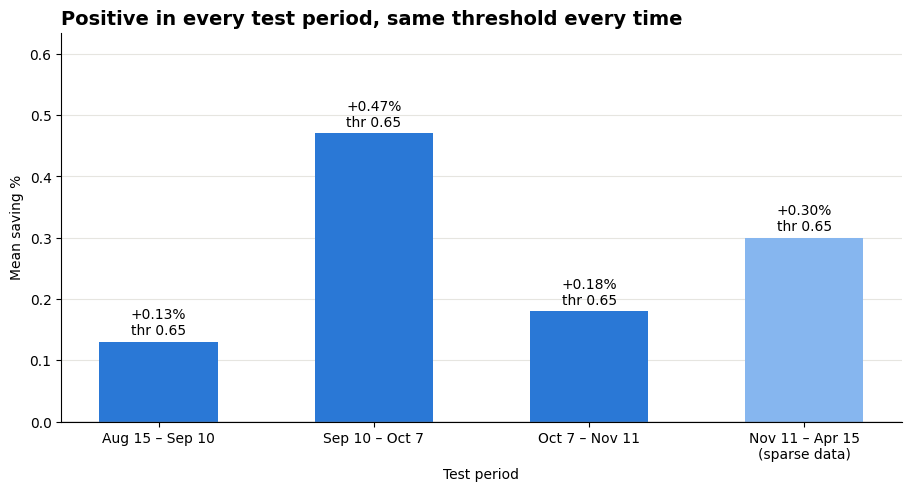

In [64]:
folds = summary.drop(columns="mean").loc["ALL"]
labels = ["Aug 15 – Sep 10", "Sep 10 – Oct 7", "Oct 7 – Nov 11", "Nov 11 – Apr 15\n(sparse data)"]
colors = [MODEL, MODEL, MODEL, "#86b6ef"]          # sparse fold lighter

fig, ax = plt.subplots(layout="constrained")
bars = ax.bar(labels, folds.values, color=colors, width=0.55)
ax.bar_label(bars, labels=[f"+{v:.2f}%\nthr 0.65" for v in folds.values], padding=3)
ax.axhline(0, color="gray", linewidth=1)
ax.set_ylabel("Mean saving %")
ax.set_xlabel("Test period")
ax.set_title("Positive in every test period, same threshold every time")
ax.set_ylim(0, folds.max() * 1.35)                 # room for labels
fig.savefig("02_rolling_folds.png", dpi=150, bbox_inches="tight")

- **Positive in all 4 periods**, average **+0.26%** over the 3 dense ones.
- Validation picked **the same threshold (0.65) every time**, without me forcing it. A good sign of stability.
- The first period is the weakest because it has the least training data.
- The last period still works even though the scraper ran only every 4–8 days there.

In [29]:
# rule based prediction 

LOWCOST = {"Ryanair", "easyJet", "Wizz Air", "Vueling", "Norwegian", "Eurowings",
           "Frontier", "Southwest", "Spirit", "Volotea", "Transavia", "Jet2", "Pegasus"}

def add_rule_cols(p):
    p = p.copy()
    p["carrier"] = np.where(p["airline_name"].astype(str).isin(LOWCOST), "low-cost", "network")
    p["move"] = (pd.cut(p["chg_1_%"], [-np.inf, -5, 5, 20, np.inf],
                        labels=["drop>5", "flat", "up 5-20", "jump>20"])
                   .cat.add_categories("first seen").fillna("first seen"))
    p["gain"] = gain(p)    
    p["above_min"]   = pd.cut(p["vs-min_so_far_%"], [-np.inf, 5, 20, 40, np.inf],
                              labels=["<5", "5-20", "20-40", ">40"])            # % saved if you wait (negative = you overpaid)
    return p

tr, va, te = add_rule_cols(train_df), add_rule_cols(val_df), add_rule_cols(test_df)

def seg_table(keys, min_tr=5000, min_va=2000, min_gain=0.5):
    t = pd.concat({
        "train": tr.groupby(keys, observed=True)["gain"].agg(["mean", "size"]),
        "val":   va.groupby(keys, observed=True)["gain"].agg(["mean", "size"]),
    }, axis=1)
    t.columns = ["_".join(c) for c in t.columns]
    t["stable"] = ((t["train_mean"] > min_gain) & (t["val_mean"] > min_gain)
                   & (t["train_size"] >= min_tr) & (t["val_size"] >= min_va))
    return t.round(2)

t2 = seg_table(["carrier", "bucket"])
display(t2)

t3 = seg_table(["carrier", "bucket", "move"])
display(t3[t3["stable"]].sort_values("val_mean", ascending=False))


far = lambda t: t[t.index.get_level_values("bucket").isin([60, 90])]
display(far(seg_table(["carrier", "bucket", "above_min"])).loc[lambda t: t["stable"]])
display(far(seg_table(["carrier","bucket", "move", "above_min"])).loc[lambda t: t["stable"]])

train_mean  train_size   val_mean  val_size  stable
carrier  bucket                                                     
low-cost 3       -16.040001       32145 -13.600000     10370   False
         7       -23.320000      190290 -23.309999     58512   False
         14      -25.750000      195742 -26.940001     54288   False
         30      -12.680000      386866 -12.940000     90183   False
         60       -4.230000      370404  -7.520000     58487   False
         90        0.340000      314241  -2.750000     26992   False
network  3       -10.800000      110459  -8.740000     33926   False
         7       -16.600000      642133 -16.480000    191128   False
         14      -19.990000      639101 -22.840000    174870   False
         30      -14.850000     1247634 -18.520000    287030   False
         60       -9.730000     1172262 -14.170000    190942   False
         90       -2.560000      974191  -5.920000     92614   False

train_mean  train_size  val_mean  val_size  stable
carrier  bucket move                                                       
low-cost 90     jump>20        8.87       19493      4.36      2522    True
         60     jump>20        5.43       43507      1.97     10104    True
network  90     jump>20        5.87       34983      1.70      4402    True

train_mean  train_size  val_mean  val_size  stable
carrier  bucket above_min                                                    
low-cost 90     20-40            3.93       22996      1.62      2602    True
                >40             11.83       19474      8.12      2173    True
network  90     >40              5.97       33048      2.44      4073    True

,,,,train_mean,train_size,val_mean,val_size,stable
carrier,bucket,move,above_min,,,,,
low-cost,60,jump>20,>40,8.08,28279,3.59,7449,True
network,90,jump>20,>40,8.18,14718,4.90,2057,True


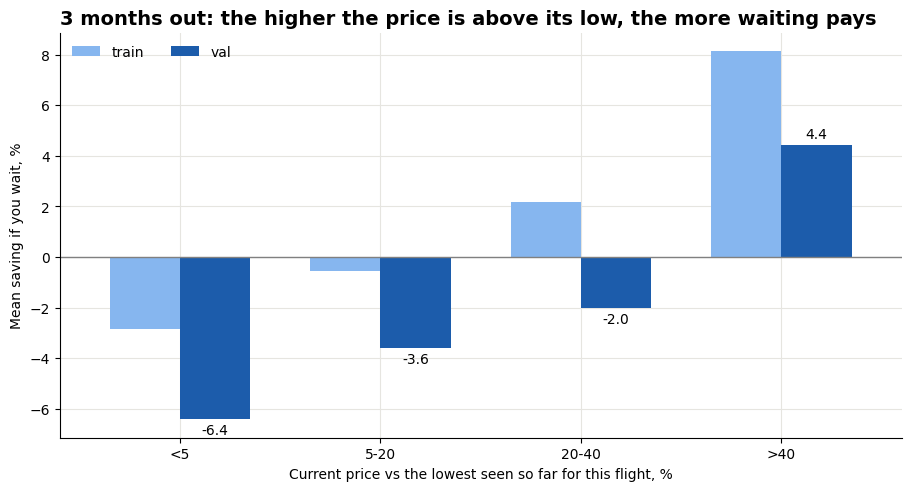

In [68]:
order = ["<5", "5-20", "20-40", ">40"]
f90 = lambda p: p[p["bucket"].eq(90)].groupby("above_min", observed=True)["gain"].mean()
d = pd.DataFrame({"train": f90(tr), "val": f90(va)}).reindex(order)

fig, ax = plt.subplots(layout="constrained")
d.plot(kind="bar", ax=ax, color=["#86b6ef", "#1c5cab"], rot=0, width=0.7)
ax.bar_label(ax.containers[1], fmt="%.1f", padding=3)     # label val only
ax.axhline(0, color="gray", linewidth=1)
ax.set_ylabel("Mean saving if you wait, %")
ax.set_xlabel("Current price vs the lowest seen so far for this flight, %")
ax.set_title("3 months out: the higher the price is above its low, the more waiting pays")
ax.legend(loc="upper left", ncols=2)
fig.savefig("03_above_min_90d.png", dpi=150, bbox_inches="tight")


In [33]:
RULES = {   # frozen before test. R1 = primary rule
    "R1 90d & >40% above min":         lambda p: p["bucket"].eq(90) & p["above_min"].eq(">40"),
    "R2 60d & jump>20 & >40% above min & low-cost":
                                       lambda p: p["bucket"].eq(60) & p["move"].eq("jump>20") & p["above_min"].eq(">40") & p["carrier"].eq("low-cost"),
    "R2.1 90d & jump>20 & >40% above min & network":
                                       lambda p: p["bucket"].isin([90]) & p["move"].eq("jump>20") & p["above_min"].eq(">40") & p["carrier"].eq("network"),
    "R3 90d & jump>20":                lambda p: p["bucket"].eq(90) & p["move"].eq("jump>20"),
}
FOLDS = [  # (val_start, test_start, test_end)
    ("2025-07-20", "2025-08-15", "2025-09-10"),
    ("2025-08-15", "2025-09-10", "2025-10-07"),
    ("2025-09-10", "2025-10-07", "2025-11-11"),   
    ("2025-10-07", "2025-11-11", "2026-04-15"),   # sparse period = stress test
]
policies = {
    "always buy":   np.zeros(len(te), bool),
    "always wait":  np.ones(len(te), bool),
    **{n: r(te).fillna(False).to_numpy(bool) for n, r in RULES.items()},
}
FOLDS = [  # (val_start, test_start, test_end)
    ("2025-07-20", "2025-08-15", "2025-09-10"),
    ("2025-08-15", "2025-09-10", "2025-10-07"),
    ("2025-09-10", "2025-10-07", "2025-11-11"),
    ("2025-10-07", "2025-11-11", "2026-04-15"),   # sparse period = stress test
]

def rules_fold(test_start, test_end):
    ts, tend = map(pd.Timestamp, (test_start, test_end))
    p = add_rule_cols(df[(df["price_datetime"] >= ts) & (df["window_end"] < tend)])
    masks = {n: r(p).fillna(False).to_numpy(bool) for n, r in RULES.items()}
    g = gain(p).to_numpy()
    stats = {}
    for n, m in masks.items():
        stats[n] = {
            "mean when wait":   g[m].mean(),          # avg % saved when the rule says WAIT
            "median when wait": np.median(g[m]),
            "win share":        (g[m] > 0).mean(),    # how often waiting actually paid off
            "fires on":         m.mean(),             # share of all rows where the rule says WAIT
            "n rows":           m.sum(),
            "ALL rows":         np.where(m, g, 0).mean(),   # comparable to the model's ALL number
        }
    return pd.DataFrame(stats).T

res = {f[1]: rules_fold(f[1], f[2]) for f in FOLDS}
label = lambda d: f"{d} (in-sample)" if d < "2025-10-07" else d

for metric in ["mean when wait", "median when wait", "win share", "fires on", "n rows", "ALL rows"]:
    t = pd.DataFrame({label(k): r[metric] for k, r in res.items()})
    print(f"\n{metric}:")
    display(t.round(4 if metric == "fires on" else 2))


mean when wait:


,2025-08-15 (in-sample),2025-09-10 (in-sample),2025-10-07,2025-11-11
R1 90d & >40% above min,5.99,4.42,1.19,13.12
R2 60d & jump>20 & >40% above min & low-cost,6.31,3.59,1.43,-1.14
R2.1 90d & jump>20 & >40% above min & network,6.65,4.90,1.10,12.27
R3 90d & jump>20,6.12,2.67,-0.33,7.21



median when wait:


,2025-08-15 (in-sample),2025-09-10 (in-sample),2025-10-07,2025-11-11
R1 90d & >40% above min,9.08,7.66,3.18,13.80
R2 60d & jump>20 & >40% above min & low-cost,13.04,10.94,9.50,7.01
R2.1 90d & jump>20 & >40% above min & network,8.02,4.38,0.03,11.94
R3 90d & jump>20,10.09,7.75,0.94,9.62



win share:


...

,2025-08-15 (in-sample),2025-09-10 (in-sample),2025-10-07,2025-11-11
R1 90d & >40% above min,0.0044,0.0049,0.0111,0.0025
R2 60d & jump>20 & >40% above min & low-cost,0.0037,0.0059,0.0072,0.0071
R2.1 90d & jump>20 & >40% above min & network,0.0012,0.0016,0.0037,0.0013
R3 90d & jump>20,0.0042,0.0055,0.0111,0.0046



n rows:


,2025-08-15 (in-sample),2025-09-10 (in-sample),2025-10-07,2025-11-11
R1 90d & >40% above min,5318.0,6246.0,14478.0,3557.0
R2 60d & jump>20 & >40% above min & low-cost,4499.0,7449.0,9405.0,10213.0
R2.1 90d & jump>20 & >40% above min & network,1402.0,2057.0,4815.0,1821.0
R3 90d & jump>20,5053.0,6924.0,14550.0,6563.0



ALL rows:


,2025-08-15 (in-sample),2025-09-10 (in-sample),2025-10-07,2025-11-11
R1 90d & >40% above min,0.03,0.02,0.01,0.03
R2 60d & jump>20 & >40% above min & low-cost,0.02,0.02,0.01,-0.01
R2.1 90d & jump>20 & >40% above min & network,0.01,0.01,0.00,0.02
R3 90d & jump>20,0.03,0.01,-0.00,0.03


**Rules tested** (the first two periods were used to find the rules, so only the last two are honest):

| Rule | Oct 7 – Nov 11 | Nov 11 – Apr 15 |
|---|---|---|
| **R1: 90 days out & price 40%+ above its low** | wins 55%, median +3.2% | wins 68%, median +13.8% |
| R2: low-cost, 60 days, price just jumped 20%+ | median +9.5% | mean −1.1% ❌ |
| R3: 90 days & price just jumped 20%+ | mean −0.3% ❌ | mean +7.2% |

**R1 is the only rule that holds in every period.** R2 and R3 break in one of them.
R1 fires on less than 1% of searches, so over *all* searches it adds only ~0.03%.
It's precise, but rare.

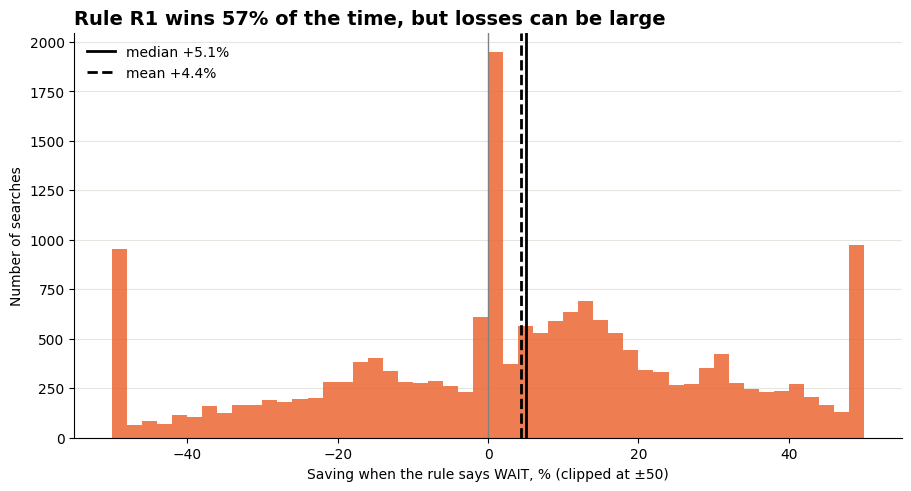

In [69]:
parts = [add_rule_cols(df[(df["price_datetime"] >= s) & (df["window_end"] < e)])
         for s, e in [("2025-10-07", "2025-11-11"), ("2025-11-11", "2026-04-15")]]
p = pd.concat(parts)
g = gain(p)[RULES["R1 90d & >40% above min"](p).fillna(False)].clip(-50, 50)

fig, ax = plt.subplots(layout="constrained")
ax.hist(g, bins=50, color=RULE, alpha=0.85)
ax.axvline(0, color="gray", linewidth=1)
ax.axvline(g.median(), color="black", linewidth=2, label=f"median {g.median():+.1f}%")
ax.axvline(g.mean(), color="black", linewidth=2, linestyle="--", label=f"mean {g.mean():+.1f}%")
ax.set_xlabel("Saving when the rule says WAIT, % (clipped at ±50)")
ax.set_ylabel("Number of searches")
ax.set_title(f"Rule R1 wins {(g > 0).mean():.0%} of the time, but losses can be large")
ax.legend(loc="upper left")
fig.savefig("04_rule_r1_distribution.png", dpi=150, bbox_inches="tight")

When R1 says wait, the typical result is good (median +5%) and it wins 57% of the time.
But the tails are wide: some waits lose 50%+, when the alert never fires and the price keeps going up.
It's a reasonable bet, not a guarantee

## Conclusions

1. **Don't just wait.** Waiting by default loses 13–27%: flight prices mostly rise toward departure.
2. **The model saves a small but stable amount**: +0.13…+0.47% per search, positive in every test period.
   That's ~5% of what perfect foresight could save, so most drops are just unpredictable.
3. **Simple rule worth remembering:** *if the flight is ~3 months away and the price is 40%+ above the
   lowest you've seen, set a −3% alert and wait.* Otherwise, buy.
4. **Use the model once per decision**, not at every price check. Re-asking it loses money.


### Limitations
- **Seasons not seen in training** (December holidays) break the long-horizon predictions.
- **The scraper ran irregularly** after Nov 2025, so some price drops were missed and
  the "true" savings are probably a bit underestimated.
- Only ~9 months of data: one of each season at most.